# Responsible AI: explaining a bank marketing model

This is my notebook for the Responsible AI module of the PwC Switzerland Digital Intelligence job simulation on Forage. A bank wanted to understand how a model that chooses which clients to call about term deposits reaches its decisions. I trained a classifier on the public UCI Bank Marketing data and used SHAP to explain it, first across the whole test set and then for observations #4 and #20.

The data is not included in this repo, so see the README for how to download it. Outputs that printed rows of the data have been cleared, and the charts and summary results are kept.

## Load Required Libraries

In [99]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

%matplotlib inline

SEED = 123456

import lime
import lime.lime_tabular
import shap

## Data inspection

The data is the UCI Bank Marketing file `bank-additional-full.csv`, which has 41,188 rows separated by semicolons. Each row has 20 input features and a target `y` that records whether the client subscribed to a term deposit.

The features describe the client (age, job, marital status, education and existing loans), the last contact in the current campaign (channel, month, weekday and call duration) and any earlier campaigns. Five more columns are economic indicators: `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m` and `nr.employed`. The full variable descriptions are on the [UCI page](https://archive.ics.uci.edu/dataset/222/bank+marketing).

In [100]:
data_path = Path("./data")
df = pd.read_csv(filepath_or_buffer=data_path / "bank-additional-full.csv", sep=";")

In [101]:
df.tail()

In [102]:
# inspect dataframe structure and null values
df.shape, df.info(), df.describe(), df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

((41188, 21),
 None,
                age      duration      campaign         pdays      previous  \
 count  41188.00000  41188.000000  41188.000000  41188.000000  41188.000000   
 mean      40.02406    258.285010      2.567593    962.475454      0.172963   
 std       10.42125    259.279249      2.770014    186.910907      0.494901   
 min       17.00000      0.000000      1.000000      0.000000      0.000000   
 25%       32.00000    102.000000      1.000000    999.000000      0.000000   
 50%       38.00000    180.000000      2.000000    999.000000      0.000000   
 75%       47.00000    319.000000      3.000000    999.000000      0.000000   
 max       98.00000   4918.000000     56.000000    999.000000      7.000000   
 
        emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   nr.employed  
 count  41188.000000    41188.000000   41188.000000  41188.000000  41188.000000  
 mean       0.081886       93.575664     -40.502600      3.621291   5167.035911  
 std        1.570960

Cleaned dataset, no missing value founded. 

Due to we have a binary prediction / classification problem, convert the `y` attribute to numeric interpretation. Convert other attributes use label encoding method.

In [159]:
df = pd.get_dummies(df, drop_first=True)
df.tail()

## Modelling

In [160]:
# train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df.drop("y_yes", axis=1), df.y_yes, random_state=SEED, test_size=0.2
)

In [161]:
# define base model
model = LogisticRegressionCV(n_jobs=1, random_state=SEED, max_iter=1000)

# fit model
model.fit(X_train, y_train)

LogisticRegressionCV(max_iter=1000, n_jobs=1, random_state=123456)

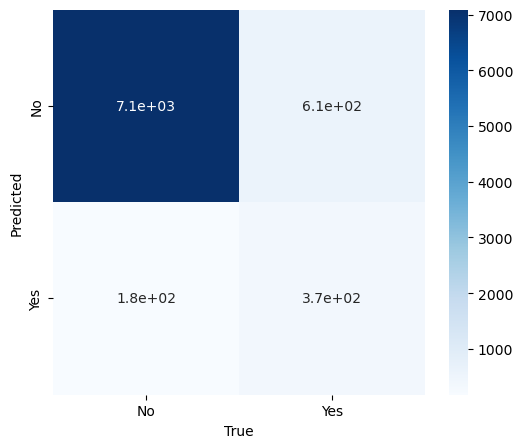

In [162]:
# generate a confusion matrix
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

# plot a confusion matrix
plt.figure(figsize=(6, 5))
ax = sns.heatmap(
    cm.T, xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], annot=True, cmap="Blues"
)
ax.set_xlabel("True")
ax.set_ylabel("Predicted")
plt.show()

In [109]:
# compute evaluation statistics
report = classification_report(y_test, y_pred, target_names=["No", "Yes"])
print(report)

              precision    recall  f1-score   support

          No       0.92      0.98      0.95      7263
         Yes       0.67      0.38      0.48       975

    accuracy                           0.90      8238
   macro avg       0.80      0.68      0.72      8238
weighted avg       0.89      0.90      0.89      8238



### Explain model use SHAP

In [163]:
explainer = shap.Explainer(model, X_train)

In [164]:
shap_values = explainer(X_test)

In [138]:
# compute SHAP values
shap_values = explainer(X_test)

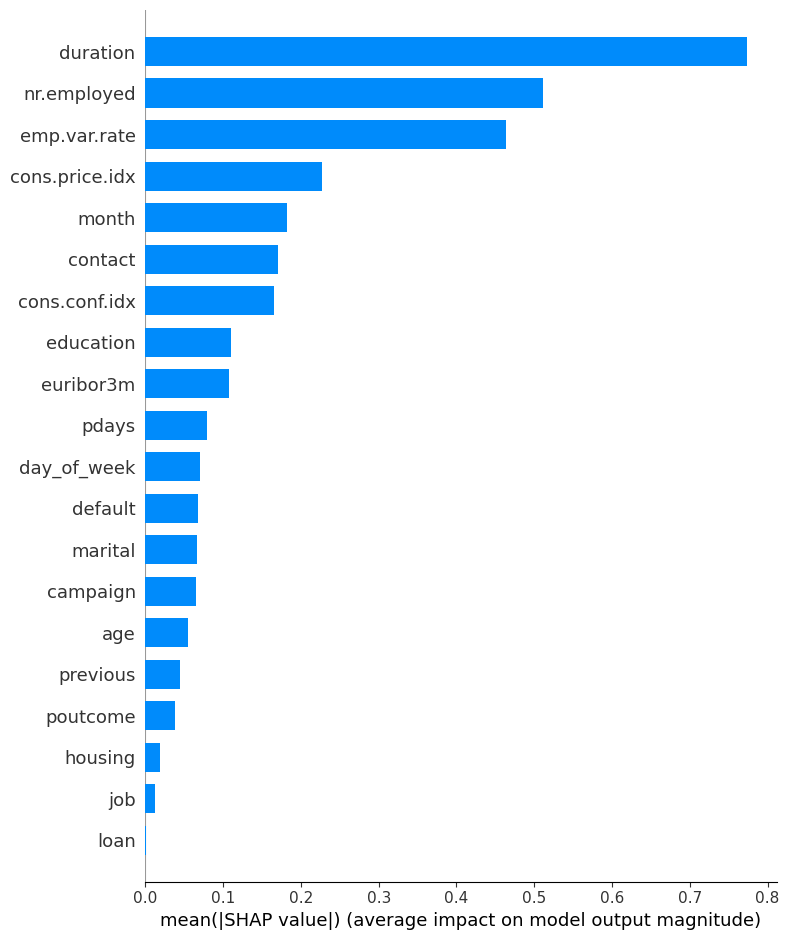

In [165]:
global_importance = shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
global_importance

In [168]:
shap.initjs()

observation_4 = shap.force_plot(
    explainer.expected_value, shap_values.values[4, :], X_test.iloc[4, :], show=False
)
observation_20 = shap.force_plot(
    explainer.expected_value, shap_values.values[20, :], X_test.iloc[20, :], show=False
)

For observation #4, the most important features influencing the prediction are nr.employed, euribor3m, and pdays, which have high SHAP values.

In [172]:
observation_4

For observation #20, the most important features are nr.employed, euribor3m, and emp.var.rate.

In [173]:
observation_20